In [1]:
import numpy as np
import pandas as pd

In [2]:
df=pd.read_csv("customer_segmentation.csv")

In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [5]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [6]:
df.dropna(inplace=True)     # Removing the missing values

In [7]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
dtype: int64

In [8]:
df['Dt_Customer']=pd.to_datetime(df["Dt_Customer"],dayfirst=True )

In [9]:
df["Age"]=2026-df['Year_Birth']   

In [10]:
df['Total_children']=df['Kidhome']+df['Teenhome']

In [11]:
df['Total_spend']=df['MntWines']+df['MntFruits']+df['MntMeatProducts']+df['MntFishProducts']+df['MntSweetProducts']+df['MntGoldProds']

In [12]:
currentDate = pd.to_datetime("2026-10-08")
df['Customer_since']=(currentDate-df['Dt_Customer']).dt.days

In [13]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Total_children,Total_spend,Customer_since
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,3,11,1,69,0,1617,5147
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,3,11,0,72,2,27,4597
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,3,11,0,61,0,776,4796
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,3,11,0,42,1,53,4623
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,3,11,0,45,1,422,4645


In [14]:
features=['Age','Income','Total_spend', 'NumWebPurchases', 'NumStorePurchases','Recency','NumWebVisitsMonth','Customer_since']

In [15]:
df_train=df[features]

In [16]:
df_train.head(5)

,Age,Income,Total_spend,NumWebPurchases,NumStorePurchases,Recency,NumWebVisitsMonth,Customer_since
0,69,58138.0,1617,8,4,58,7,5147
1,72,46344.0,27,1,2,38,5,4597
2,61,71613.0,776,8,10,26,4,4796
3,42,26646.0,53,2,4,26,6,4623
4,45,58293.0,422,5,6,94,5,4645


In [17]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
scaled=sc.fit_transform(df_train)

In [18]:
#Applying kmeans clustering
from sklearn.cluster import KMeans

In [19]:
k_n=range(2,10)
ssc=[]

for i in k_n:
    km=KMeans(n_clusters=i)
    km.fit(scaled)
    ssc.append(km.inertia_)

In [20]:
ssc

[12419.362344457986,
 11363.189404532446,
 10121.170803352756,
 9612.637687499728,
 8994.877617907976,
 8678.96711638569,
 8249.698689730003,
 8027.693433582441]

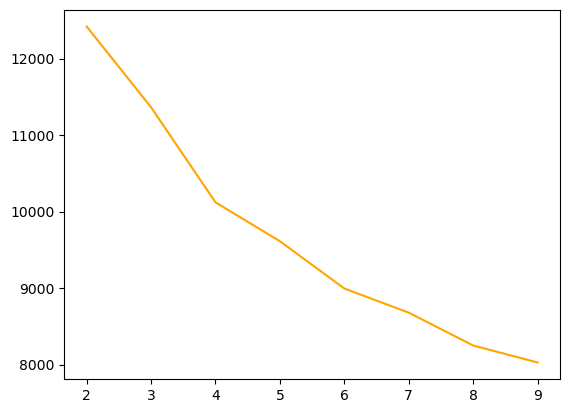

In [21]:
import matplotlib.pyplot as plt
plt.plot(k_n,ssc,color='orange')
plt.show()

In [22]:
k_means=KMeans(n_clusters=4)
k_means.fit(scaled)

KMeans(n_clusters=4)

In [23]:
k_means.labels_

array([1, 0, 1, ..., 3, 3, 2], dtype=int32)

In [24]:
df_train["Clusters"]=(k_means.labels_)

C:\Users\User\AppData\Local\Temp\ipykernel_6828\2842199481.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train["Clusters"]=(k_means.labels_)


In [25]:
df_train.head(5)

,Age,Income,Total_spend,NumWebPurchases,NumStorePurchases,Recency,NumWebVisitsMonth,Customer_since,Clusters
0,69,58138.0,1617,8,4,58,7,5147,1
1,72,46344.0,27,1,2,38,5,4597,0
2,61,71613.0,776,8,10,26,4,4796,1
3,42,26646.0,53,2,4,26,6,4623,0
4,45,58293.0,422,5,6,94,5,4645,0


In [26]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
pca_data=pca.fit_transform(scaled)

In [27]:
df_train['PCA1'],df_train['PCA2']=pca_data[:,0],pca_data[:,1]

C:\Users\User\AppData\Local\Temp\ipykernel_6828\1560774053.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train['PCA1'],df_train['PCA2']=pca_data[:,0],pca_data[:,1]
C:\Users\User\AppData\Local\Temp\ipykernel_6828\1560774053.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train['PCA1'],df_train['PCA2']=pca_data[:,0],pca_data[:,1]


In [28]:
df_train.head()

,Age,Income,Total_spend,NumWebPurchases,NumStorePurchases,Recency,NumWebVisitsMonth,Customer_since,Clusters,PCA1,PCA2
0,69,58138.0,1617,8,4,58,7,5147,1,1.187690,2.045176
1,72,46344.0,27,1,2,38,5,4597,0,-1.399134,-1.616527
2,61,71613.0,776,8,10,26,4,4796,1,1.873884,0.143160
3,42,26646.0,53,2,4,26,6,4623,0,-1.832613,-0.853036
4,45,58293.0,422,5,6,94,5,4645,0,-0.021754,-0.582447


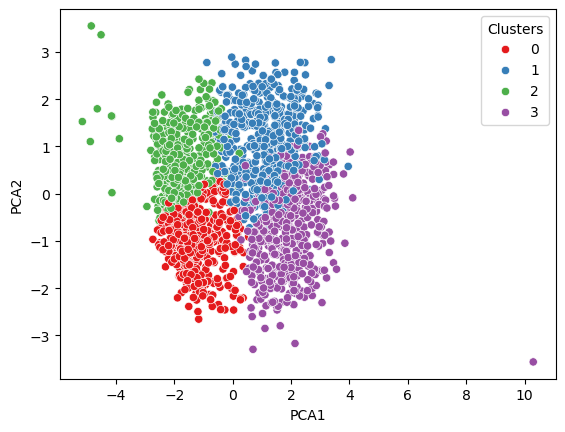

In [29]:
import seaborn as sns
sns.scatterplot(x='PCA1',y='PCA2',data=df_train,hue='Clusters',palette='Set1')
plt.show()

In [30]:

from sklearn.metrics import silhouette_score
# Evaluate existing K-Means model
silhouette = silhouette_score(scaled, k_means.labels_)


print("Silhouette Score:",silhouette)


Silhouette Score: 0.16479877757672626


In [31]:
from sklearn.mixture import GaussianMixture
bic_scores = []

for k in range(2, 10):
    gm = GaussianMixture(n_components=k, random_state=42)
    gm.fit(scaled)
    bic_scores.append(gm.bic(scaled))

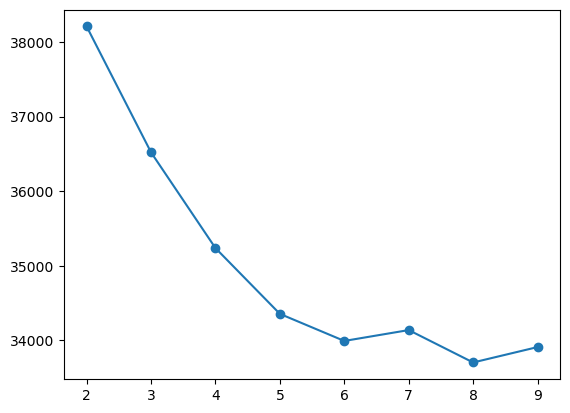

In [32]:
plt.plot(range(2, 10), bic_scores, marker='o')
plt.show()

In [33]:
gmm = GaussianMixture(n_components=8, random_state=42)
gmm.fit(scaled)

gmm_labels = gmm.predict(scaled)

In [34]:
gmm_score = silhouette_score(scaled, gmm_labels)
print("GMM Silhouette Score:", gmm_score)

GMM Silhouette Score: 0.070199551071711


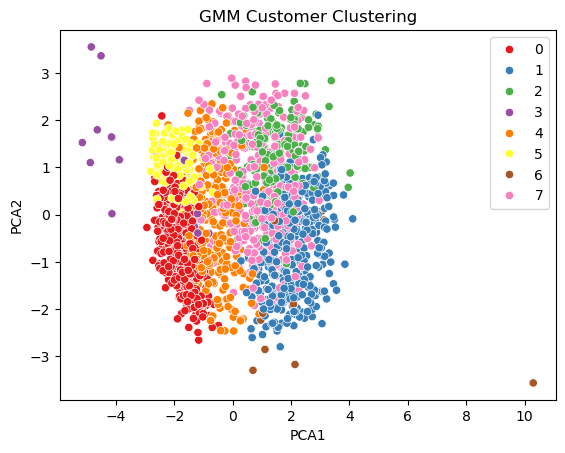

In [35]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled)

sns.scatterplot(
    x=pca_data[:, 0],
    y=pca_data[:, 1],
    hue=gmm_labels,
    palette='Set1'
)

plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.title('GMM Customer Clustering')
plt.show()

**Final thoughts**

From the notebook, we can see that by using K-means clustering, we can cluster our customers into four separate clusters. The silhouette score of K-means clustering is 0.164. Also, by using Gaussian mixture, our silhouette score is 0.70.The best n component was for it 8.  In both the cases, the clustering is quite weak.But there are ways to improve the silhouette score value. Maybe with more time we can remove unusual values. We can experiment with other features and use other values or other number of clusters.